# SMS Spam Detection Using a Neural Network
### Complete step-by-step project with TensorFlow/Keras

**Objective:** Train a neural network to classify SMS messages as **ham** (legitimate) or **spam**.

This notebook covers:
1. Importing libraries and loading the dataset
2. Exploring and cleaning the data
3. Splitting data into training and test sets
4. Converting text into sequences and padding them
5. Building and training a neural network
6. Evaluating performance with metrics and visualizations
7. Testing the model on new messages
8. Saving the trained model and tokenizer

**Dataset:** [UCI SMS Spam Collection on Kaggle](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)

## By: Ahmed Adel El Sawy        2305238


## 1. Import the required libraries

We use:
- **pandas / NumPy** for handling the dataset
- **Matplotlib / Seaborn** for charts
- **scikit-learn** for splitting data and evaluation metrics
- **TensorFlow/Keras** for text preprocessing and the neural network


In [76]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: []


## 2. Load the dataset

The common Kaggle file is `spam.csv`. It often contains columns named `v1` and `v2`, where `v1` is the label and `v2` is the message. The code below detects common column names and standardizes them to `label` and `message`.


In [77]:
# Change this path if your CSV is stored somewhere else.
DATA_PATH = "spam.csv"

if not os.path.exists(DATA_PATH):
    alternatives = ["SMSSpamCollection", "SMSSpamCollection.csv", "sms_spam.csv"]
    found = next((p for p in alternatives if os.path.exists(p)), None)
    if found:
        DATA_PATH = found
    else:
        raise FileNotFoundError(
            "Dataset file not found. Download spam.csv from the Kaggle dataset "
            "and place it beside this notebook, or update DATA_PATH."
        )

# Kaggle's spam.csv commonly has an extra unnamed column and may use latin-1 encoding.
try:
    raw_df = pd.read_csv(DATA_PATH, encoding="latin-1")
except Exception:
    raw_df = pd.read_csv(DATA_PATH)

print("Original shape:", raw_df.shape)
display(raw_df.head())
print("Columns:", raw_df.columns.tolist())


Original shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


## 3. Clean and inspect the data

We map `ham` to **0** and `spam` to **1**. Then we remove missing rows and duplicate messages. Removing duplicates helps avoid the same text appearing repeatedly in the evaluation data.


In [78]:
# Identify label and message columns across common dataset versions.
lower_to_original = {str(c).strip().lower(): c for c in raw_df.columns}

label_candidates = ["v1", "label", "class", "category", "type"]
message_candidates = ["v2", "message", "sms", "text", "content"]

label_col = next((lower_to_original[c] for c in label_candidates if c in lower_to_original), None)
message_col = next((lower_to_original[c] for c in message_candidates if c in lower_to_original), None)

if label_col is None or message_col is None:
    # The UCI original tab-separated file may load as two columns without headers.
    if raw_df.shape[1] >= 2:
        raw_df = raw_df.iloc[:, :2].copy()
        raw_df.columns = ["label", "message"]
    else:
        raise ValueError("Could not identify label/message columns. Inspect raw_df.columns.")

df = raw_df[[label_col, message_col]].copy()
df.columns = ["label", "message"]
df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()
df = df[df["label"].isin(["ham", "spam"])]
df = df[df["message"] != ""]
df = df.drop_duplicates(subset=["message"]).reset_index(drop=True)
df["target"] = df["label"].map({"ham": 0, "spam": 1}).astype(int)

print("Cleaned shape:", df.shape)
print("\nClass counts:")
display(df["label"].value_counts().rename_axis("label").to_frame("count"))
display(df.head())


Cleaned shape: (5158, 3)

Class counts:


,count
label,
ham,4516
spam,642


,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 4. Explore the class distribution

Spam datasets usually contain many more ham messages than spam messages. This is called **class imbalance**, so we should look at more than accuracy when evaluating the model.


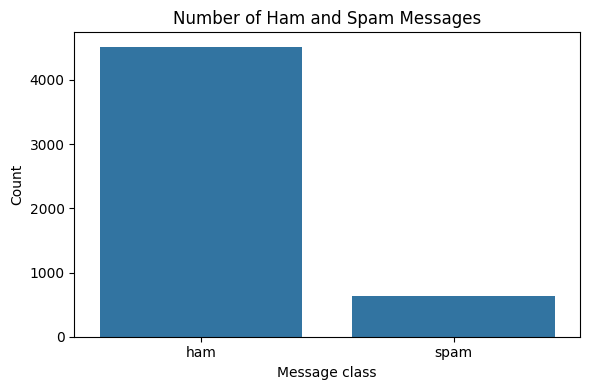

Ham percentage:  87.55%
Spam percentage: 12.45%


In [79]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=["ham", "spam"])
plt.title("Number of Ham and Spam Messages")
plt.xlabel("Message class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print("Ham percentage:  {:.2f}%".format((df["target"] == 0).mean() * 100))
print("Spam percentage: {:.2f}%".format((df["target"] == 1).mean() * 100))


## 5. Split the data into training and test sets

We reserve 20% of the data for final testing. `stratify=y` keeps approximately the same ham/spam ratio in both sets. The test set is not used to train the model.


In [80]:
X = df["message"].astype(str).to_numpy()
y = df["target"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages: ", len(X_test))
print("Spam rate in training set: {:.2f}%".format(y_train.mean() * 100))
print("Spam rate in test set:     {:.2f}%".format(y_test.mean() * 100))


Training messages: 4126
Testing messages:  1032
Spam rate in training set: 12.46%
Spam rate in test set:     12.40%


## 6. Convert text into numbers

Neural networks operate on numbers, not raw words. We use Keras' `TextVectorization` layer to:
- standardize text (including lowercasing and punctuation handling),
- learn a vocabulary from **training messages only**,
- convert each message into a sequence of integer token IDs,
- pad or truncate sequences to a common length.

The vectorization layer is included in the model, so raw text can be passed to the model at prediction time.


In [81]:
MAX_TOKENS = 10000
SEQUENCE_LENGTH = 100

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation"
)

# Learn vocabulary only from training messages to avoid test-data leakage.
text_ds = tf.data.Dataset.from_tensor_slices(X_train).batch(64)
vectorizer.adapt(text_ds)

vocab = vectorizer.get_vocabulary()
print("Vocabulary size (including reserved tokens):", len(vocab))
print("Example vocabulary entries:", vocab[:20])

example_message = X_train[0]
print("\nExample message:", example_message)
print("Token IDs:", vectorizer(tf.constant([example_message])).numpy()[0][:30])


Vocabulary size (including reserved tokens): 8276
Example vocabulary entries: ['', '[UNK]', np.str_('to'), np.str_('i'), np.str_('you'), np.str_('a'), np.str_('the'), np.str_('u'), np.str_('and'), np.str_('in'), np.str_('is'), np.str_('me'), np.str_('my'), np.str_('for'), np.str_('your'), np.str_('it'), np.str_('of'), np.str_('have'), np.str_('that'), np.str_('on')]

Example message: Call him and say you not coming today ok and tell them not to fool me like this ok
Token IDs: [  20  115    8  161    4   26  251   92   45    8   97  168   26    2
 2870   11   56   40   45    0    0    0    0    0    0    0    0    0
    0    0]


## 7. Build the neural network

Architecture:
- **TextVectorization:** converts raw SMS text into token IDs.
- **Embedding:** learns a dense vector representation for each token.
- **GlobalAveragePooling1D:** summarizes token vectors into one message vector.
- **Dense + Dropout:** learns patterns while reducing overfitting.
- **Sigmoid output:** produces a score from 0 to 1; larger values indicate a higher likelihood of spam.

We use binary cross-entropy because this is a two-class classification problem.


In [82]:
EMBEDDING_DIM = 64

text_input = tf.keras.Input(shape=(), dtype=tf.string, name="sms_text")
x = vectorizer(text_input)
x = tf.keras.layers.Embedding(
    input_dim=len(vocab),
    output_dim=EMBEDDING_DIM,
    name="word_embedding"
)(x)
x = tf.keras.layers.GlobalAveragePooling1D()(x)
x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dropout(0.30)(x)
x = tf.keras.layers.Dense(32, activation="relu")(x)
output = tf.keras.layers.Dense(1, activation="sigmoid", name="spam_probability")(x)

model = tf.keras.Model(inputs=text_input, outputs=output)
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sms_text (InputLayer)           │ (None)                 │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_vectorization_2            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ word_embedding (Embedding)      │ (None, 100, 64)        │       529,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spam_probability (Dense)        │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,937 (2.04 MB)

 Trainable params: 535,937 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train the model

We use early stopping to stop training when validation loss no longer improves and restore the best weights. A validation split is taken from the training data; the held-out test set remains untouched.


In [83]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/15


104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8697 - loss: 0.3899 - precision: 0.1875 - recall: 0.0146 - val_accuracy: 0.8741 - val_loss: 0.3577 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8758 - loss: 0.3559 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.8741 - val_loss: 0.3510 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8758 - loss: 0.3334 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.8741 - val_loss: 0.3099 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8930 - loss: 0.2497 - precision: 1.0000 - recall: 0.1390 - val_accuracy: 0.9479 - val_loss: 0.1655 - val_precision: 1.0000 - val_recall: 0.5865
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9624 - loss: 0.1218 - precision: 0.9704 - recall: 0.7195 - val_a

## 9. Visualize training and validation performance

Training and validation curves can reveal overfitting. If training performance keeps improving while validation performance worsens, the model may be memorizing the training data.


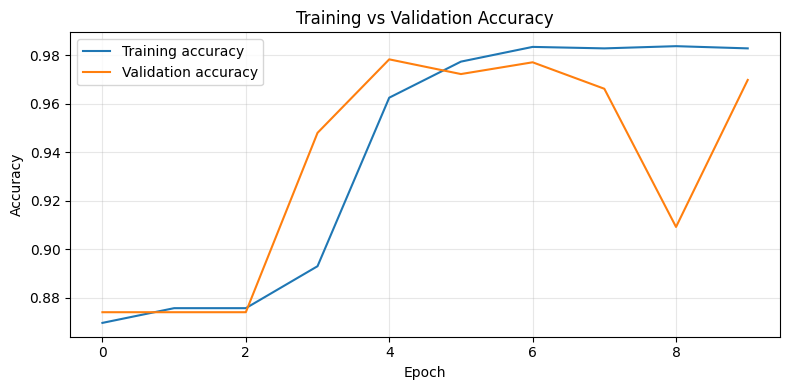

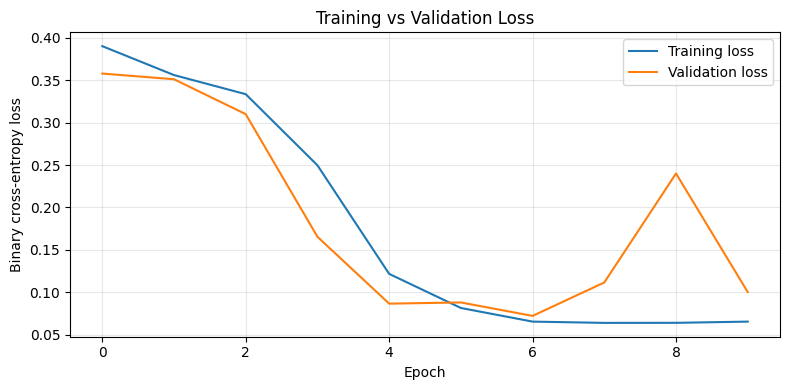

In [84]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(8, 4))
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Evaluate on the held-out test set

We predict spam probabilities, then apply a default threshold of **0.5**:
- probability >= 0.5 → spam (1)
- probability < 0.5 → ham (0)

Precision answers: “Of messages predicted as spam, how many really were spam?”
Recall answers: “Of all real spam messages, how many did we detect?”
F1-score balances precision and recall.


In [85]:
test_probabilities = model.predict(X_test, verbose=0).ravel()
THRESHOLD = 0.50
y_pred = (test_probabilities >= THRESHOLD).astype(int)

results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (spam)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (spam)": recall_score(y_test, y_pred, zero_division=0),
    "F1-score (spam)": f1_score(y_test, y_pred, zero_division=0)
}

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"], zero_division=0))


Accuracy: 0.9806
Precision (spam): 0.9500
Recall (spam): 0.8906
F1-score (spam): 0.9194

Classification report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       904
        Spam       0.95      0.89      0.92       128

    accuracy                           0.98      1032
   macro avg       0.97      0.94      0.95      1032
weighted avg       0.98      0.98      0.98      1032



## 11. Confusion matrix

The confusion matrix shows correct and incorrect classifications:
- **True ham:** ham correctly predicted as ham
- **False spam alarm:** ham incorrectly predicted as spam
- **Missed spam:** spam incorrectly predicted as ham
- **Detected spam:** spam correctly predicted as spam


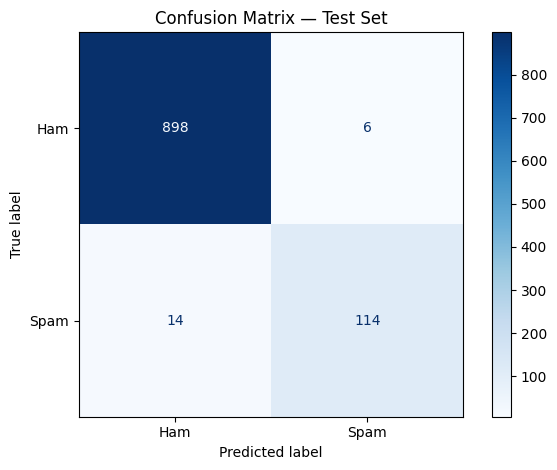

In [86]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ham", "Spam"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()


## 12. Try the model on new SMS messages

Edit the messages below or add your own. The model returns a spam probability and a predicted class. This is a demonstration; do not treat the output as a guarantee that a message is safe.


In [ ]:

new_messages = [
    "Congratulations! You have won a free prize. Call now to claim your reward!",
    "Hey, are we still meeting for lunch today?",
    "URGENT! Your account has been selected for a cash reward. Click the link now.",
    "Thanks for your help with the assignment."
]

new_probabilities = model.predict(np.array(new_messages, dtype=object), verbose=0).ravel()

new_predictions = (new_probabilities >= THRESHOLD).astype(int)

prediction_df = pd.DataFrame({
    "message": new_messages,
    "spam_probability": new_probabilities,
    "predicted_label": ["spam" if p == 1 else "ham" for p in new_predictions]
})

display(prediction_df)


,message,spam_probability,predicted_label
0,Congratulations! You have won a free prize. Ca...,0.994678,spam
1,"Hey, are we still meeting for lunch today?",0.005728,ham
2,URGENT! Your account has been selected for a c...,0.979181,spam
3,Thanks for your help with the assignment.,0.484324,ham


## 13. Optional: adjust the decision threshold

The default threshold is 0.5, but the best threshold depends on your priorities. A lower threshold may catch more spam but can also flag more legitimate messages. The chart below shows precision and recall across several thresholds.


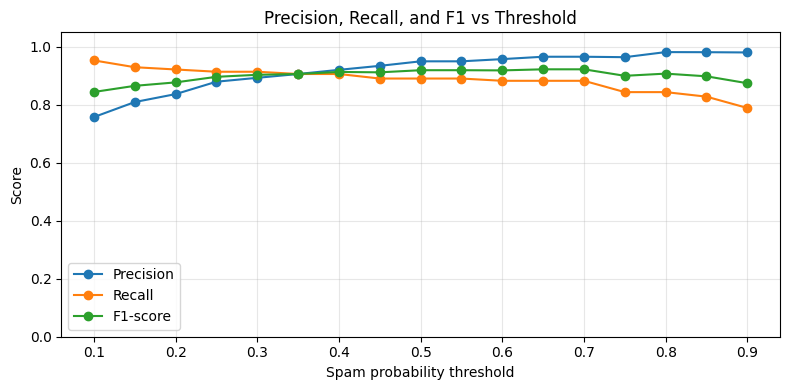

In [88]:
thresholds = np.arange(0.10, 0.91, 0.05)
precisions, recalls, f1s = [], [], []

for threshold in thresholds:
    pred_at_threshold = (test_probabilities >= threshold).astype(int)
    precisions.append(precision_score(y_test, pred_at_threshold, zero_division=0))
    recalls.append(recall_score(y_test, pred_at_threshold, zero_division=0))
    f1s.append(f1_score(y_test, pred_at_threshold, zero_division=0))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions, marker="o", label="Precision")
plt.plot(thresholds, recalls, marker="o", label="Recall")
plt.plot(thresholds, f1s, marker="o", label="F1-score")
plt.xlabel("Spam probability threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, and F1 vs Threshold")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 14. Save the trained model

The saved Keras model includes the text vectorization layer, so you can later load it and pass raw SMS strings directly to it. The model is saved in Keras' `.keras` format.


In [ ]:

WEIGHTS_PATH = "sms_spam_detector_weights.weights.h5"
model.save_weights(WEIGHTS_PATH)
print(f"Weights saved to: {WEIGHTS_PATH}")

model.load_weights(WEIGHTS_PATH)

sample_probability = float(
    model.predict(
        np.array(["You have won a free gift. Claim now!"], dtype=object),
        verbose=0,
    )[0][0]
)
print("Example spam probability after reloading weights:", round(sample_probability, 4))


Weights saved to: sms_spam_detector_weights.weights.h5
Example spam probability after reloading weights: 0.943


## 15. Conclusion

In this project, we built an end-to-end neural-network pipeline for SMS spam detection. We cleaned and explored the dataset, converted text into token IDs, trained an Embedding-based neural network, and evaluated it on unseen test messages.

### Major Points Covered
- Dataset source and number of cleaned examples
- Neural network architecture and training settings
- Training/validation accuracy and loss plots
- Test accuracy, spam precision, spam recall, and spam F1-score
- Confusion matrix
- A short discussion of false positives and missed spam

